# Weighting Ablation Analysis

This notebook analyzes the raw outputs produced by `scripts/run_ablation_weights.py`. It creates one metric-vs-hyperparameter plot for each weighting sweep: `tau`, `lam`, and `n_rounds`. Confidence bands are computed by seaborn bootstrap resampling across seeds.

In [2]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis.ablation_analysis import (
    load_ablation_metrics,
    ordered_methods,
    plot_ablation_metric_ci,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 260)
pd.set_option("display.expand_frame_repr", False)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.edgecolor"] = "black"

## Configuration

Edit `RESULTS_DIR`, `SELECTED_METRIC`, and optionally `METHODS_TO_PLOT` before running the notebook.

In [3]:
RESULTS_DIR = PROJECT_ROOT / "results" / "ablation_weights_wu2024"
ANALYSIS_DIR = RESULTS_DIR / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_METRIC = "regret"
DEFAULT_SPLIT = "test"
CONFIDENCE = 0.95
N_BOOT = 3000

# Set to None to use every method present in the ablation table.
# Example: ["Weighted PMMR", "Weighted NMMR-U", "Weighted NMMR-V"]
METHODS_TO_PLOT = None

# Set to None to use every seed present in the ablation table.
SEEDS_TO_ANALYZE = None

FIGSIZE = (7.2, 4.6)
SAVE_FIGURES = True

RESULTS_DIR, ANALYSIS_DIR

(WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/ablation_weights_wu2024'),
 WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/ablation_weights_wu2024/analysis'))

The following cell loads method order, labels, and colors from `src.analysis.plot_styles`.


In [4]:
from src.analysis.plot_styles import METHOD_ORDER, METHOD_LABELS

METHOD_COLORS = {
    "Weighted PMMR": "#1f77b4",
    "Weighted KPV": "#2ca02c",
    "Weighted DFPV": "#bcbd22",
}

display(pd.DataFrame(
    [{"method": method, "label": METHOD_LABELS.get(method, method), "color": METHOD_COLORS.get(method)} for method in METHOD_ORDER]
))

,method,label,color
0,PMMR,PMMR,NaN
1,Weighted PMMR,DA-PMMR,#1f77b4
2,NMMR-U,NMMR-U,NaN
3,Weighted NMMR-U,DA-NMMR-U,NaN
4,NMMR-V,NMMR-V,NaN
5,Weighted NMMR-V,DA-NMMR-V,NaN
6,NMMR,NMMR,NaN
7,Weighted NMMR,DA-NMMR,NaN
8,KPV,KPV,NaN
9,Weighted KPV,DA-KPV,#2ca02c


## Load Ablation Metrics

In [5]:
metrics_df = load_ablation_metrics(RESULTS_DIR)
if SEEDS_TO_ANALYZE is not None:
    metrics_df = metrics_df[metrics_df["seed"].astype(int).isin([int(seed) for seed in SEEDS_TO_ANALYZE])].copy()

available_methods = ordered_methods(metrics_df["method"].dropna().unique(), METHOD_ORDER)
if METHODS_TO_PLOT is None:
    METHODS_TO_PLOT = available_methods
else:
    METHODS_TO_PLOT = [method for method in METHODS_TO_PLOT if method in set(available_methods)]

available_parameters = [
    parameter for parameter in ["tau", "lam", "n_rounds"]
    if parameter in set(metrics_df["ablation_parameter"].astype(str))
]

print(f"Rows: {len(metrics_df)}")
print(f"Methods: {METHODS_TO_PLOT}")
print(f"Ablation parameters: {available_parameters}")
display(metrics_df.head())

Rows: 468
Methods: ['Weighted PMMR', 'Weighted KPV', 'Weighted DFPV']
Ablation parameters: ['tau', 'lam', 'n_rounds']


,dataset,seed,split,model_key,method,ablation_parameter,ablation_value,ablation_run,weighting_section,weighting_tau,weighting_lam,weighting_n_rounds,local_rmse,regret,run_dir,factual_mean_mae,factual_mean_rmse,global_rmse,mean_curve_argmax_abs_error,mean_curve_bias,mean_curve_direct_argmax_abs_error,mean_curve_direct_bias,mean_curve_direct_mae,mean_curve_direct_pred_argmax,mean_curve_direct_rmse,mean_curve_direct_true_argmax,mean_curve_mae,mean_curve_pred_argmax,mean_curve_rmse,mean_curve_true_argmax,observed_rmse,optimal_policy_value,optimal_policy_value_causal_marginal,optimal_policy_value_oracle,optimal_policy_value_structural,policy_mse,policy_mse_causal_marginal,policy_mse_oracle,policy_mse_structural,policy_value,policy_value_causal_marginal,policy_value_oracle,policy_value_structural,pseudo_outcome_iqr,pseudo_outcome_std,regret_causal_marginal,regret_oracle,regret_structural,weight_ess_final,raw_method
0,wu2024_nonadditive,1,test,weighted_dfpv,Weighted DFPV,lam,0.1,lam_0p1,weighting_dfpv,1.31,0.1,5,2.907878,8.584212,results/ablation_weights_wu2024/runs/seed_001/lam_0p1,2.675781,3.396183,5.275582,1.638807,0.265285,1.638807,1.404752,4.387176,2.35699,5.394163,0.718183,4.145101,2.356990,4.835214,0.718183,3.340704,1.124863,1.124863,1.097139,1.103893,3.390376,3.390376,3.394199,3.397035,-7.459349,-7.459349,-7.462482,-7.462794,8.782600,9.383305,8.584212,8.559621,8.566687,646.549916,Weighted DFPV
1,wu2024_nonadditive,1,validation,weighted_dfpv,Weighted DFPV,lam,0.1,lam_0p1,weighting_dfpv,1.31,0.1,5,2.897544,8.496640,results/ablation_weights_wu2024/runs/seed_001/lam_0p1,2.573703,3.326829,5.255094,1.638807,0.380470,1.638807,1.364851,4.459882,2.35699,5.451878,0.718183,4.112934,2.356990,4.827389,0.718183,3.371251,1.244155,1.244155,1.116573,1.225335,3.364731,3.364731,3.352782,3.356370,-7.252485,-7.252485,-7.377938,-7.256459,8.782600,9.383305,8.496640,8.494511,8.481794,646.549916,Weighted DFPV
2,wu2024_nonadditive,1,test,weighted_kpv,Weighted KPV,lam,0.1,lam_0p1,weighting_kpv,1.31,0.1,5,1.144636,4.245975,results/ablation_weights_wu2024/runs/seed_001/lam_0p1,2.175708,2.881156,4.194280,0.968386,1.736343,1.638807,2.033131,3.195956,2.35699,4.443997,0.718183,2.933901,1.686569,3.887780,0.718183,2.976728,1.124863,1.124863,1.097139,1.103893,1.423914,1.423914,1.426639,1.428320,-3.121111,-3.121111,-3.130688,-3.123738,4.529362,3.428761,4.245975,4.227827,4.227631,692.278732,Weighted KPV
3,wu2024_nonadditive,1,validation,weighted_kpv,Weighted KPV,lam,0.1,lam_0p1,weighting_kpv,1.31,0.1,5,1.124659,4.289522,results/ablation_weights_wu2024/runs/seed_001/lam_0p1,2.088835,2.760837,4.159107,0.968386,1.778768,1.638807,2.041235,3.313809,2.35699,4.581984,0.718183,2.954936,1.686569,3.922231,0.718183,2.824822,1.244155,1.244155,1.116573,1.225335,1.443974,1.443974,1.437259,1.439368,-3.045366,-3.045366,-3.152750,-3.044011,4.529362,3.428761,4.289522,4.269323,4.269345,692.278732,Weighted KPV
4,wu2024_nonadditive,1,test,weighted_pmmr,Weighted PMMR,lam,0.1,lam_0p1,weighting_pmmr,1.31,0.1,5,1.522149,6.670217,results/ablation_weights_wu2024/runs/seed_001/lam_0p1,2.249499,2.864076,6.500747,1.489824,1.090186,1.638807,1.321690,5.612386,2.35699,6.683961,0.718183,5.183250,2.208008,6.095958,0.718183,4.467033,1.124863,1.124863,1.097139,1.103893,2.556820,2.556820,2.558334,2.559927,-5.545354,-5.545354,-5.517427,-5.547107,10.280594,7.794413,6.670217,6.614567,6.651000,654.490320,Weighted PMMR


## Summary Table

This table is useful for checking that all model/seed/sweep combinations are present before plotting.

In [6]:
summary = (
    metrics_df[metrics_df["split"].astype(str) == DEFAULT_SPLIT]
    .assign(metric_value=lambda df: pd.to_numeric(df[SELECTED_METRIC], errors="coerce"))
    .dropna(subset=["metric_value"])
    .groupby(["ablation_parameter", "ablation_value", "method"], observed=True)
    .agg(
        n=("metric_value", "size"),
        n_seeds=("seed", "nunique"),
        mean=("metric_value", "mean"),
        std=("metric_value", "std"),
    )
    .reset_index()
    .sort_values(["ablation_parameter", "ablation_value", "method"])
)
display(summary)

,ablation_parameter,ablation_value,method,n,n_seeds,mean,std
0,lam,0.10,Weighted DFPV,6,6,4.894238,2.771894
1,lam,0.10,Weighted KPV,6,6,3.372509,0.528645
2,lam,0.10,Weighted PMMR,6,6,5.032239,1.931227
3,lam,0.35,Weighted DFPV,6,6,3.523162,0.674983
4,lam,0.35,Weighted KPV,6,6,3.392297,0.592921
5,lam,0.35,Weighted PMMR,6,6,4.875833,1.887126
6,lam,1.00,Weighted DFPV,6,6,4.536453,2.276717
7,lam,1.00,Weighted KPV,6,6,3.469437,0.660729
8,lam,1.00,Weighted PMMR,6,6,4.656128,1.874569
9,lam,3.00,Weighted DFPV,6,6,5.316748,2.508949


## Ablation Figures

Each plot uses seaborn's bootstrap confidence interval directly through `lineplot(errorbar=("ci", 95))`.

C:\Users\Alex\AppData\Local\Temp\ipykernel_27260\3522405553.py:51: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


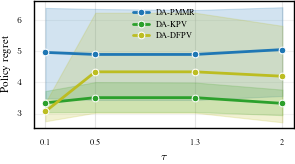

C:\Users\Alex\AppData\Local\Temp\ipykernel_27260\3522405553.py:51: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


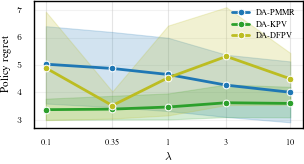

C:\Users\Alex\AppData\Local\Temp\ipykernel_27260\3522405553.py:51: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


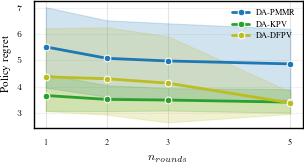

In [7]:
def save_figure(fig: plt.Figure, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=220, bbox_inches="tight", facecolor="white")



plt.rcParams.update({
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.labelcolor": "black",
})


def plot_one_parameter(parameter: str):
    fig = plot_ablation_metric_ci(
        metrics_df,
        metric=SELECTED_METRIC,
        split=DEFAULT_SPLIT,
        parameter=parameter,
        methods=METHODS_TO_PLOT,
        method_order=METHOD_ORDER,
        colors=METHOD_COLORS,
        labels=METHOD_LABELS,
        seeds=SEEDS_TO_ANALYZE,
        confidence=CONFIDENCE,
        n_boot=N_BOOT,
    )
    ax = fig.axes[0]
    x_values = (
    metrics_df.loc[metrics_df["ablation_parameter"].astype(str) == str(parameter), "ablation_value"]
    .dropna()
    .astype(float)
    .sort_values()
    .unique()
    )

    if parameter == "lam":
        ax.set_xscale("log")

    ax.set_xticks(x_values)
    ax.set_xticklabels([f"{v:g}" for v in x_values])
    ax.set_ylabel(SELECTED_METRIC)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    fig.tight_layout()
    if SAVE_FIGURES:
        stem = f"ablation_{parameter}_{SELECTED_METRIC}_{DEFAULT_SPLIT}"
        save_figure(fig, ANALYSIS_DIR / f"{stem}.png")
        save_figure(fig, ANALYSIS_DIR / f"{stem}.pdf")
    return fig, ax

from tueplots import bundles
with plt.rc_context(bundles.icml2024(column='half')):
    figures = {}
    for parameter in ["tau", "lam", "n_rounds"]:
        if parameter not in available_parameters:
            print(f"Skipping {parameter}: not present in ablation_metrics.csv")
            continue
        figures[parameter], ax = plot_one_parameter(parameter)
        ax.set_ylabel('Policy regret')
        ax.set_title("")
        if parameter == 'tau':
            ax.set_xlabel(r"$\tau$")
        elif parameter == 'lam':
            ax.set_xlabel(r"$\lambda$")
        else:
            ax.set_xlabel(r"$n_{rounds}$")
        plt.savefig(ANALYSIS_DIR / f"{parameter}_nat.pdf")
        plt.show()

## Combined View

The separate plots above are the primary outputs. This optional panel is useful for quickly comparing all three sweeps in one row.

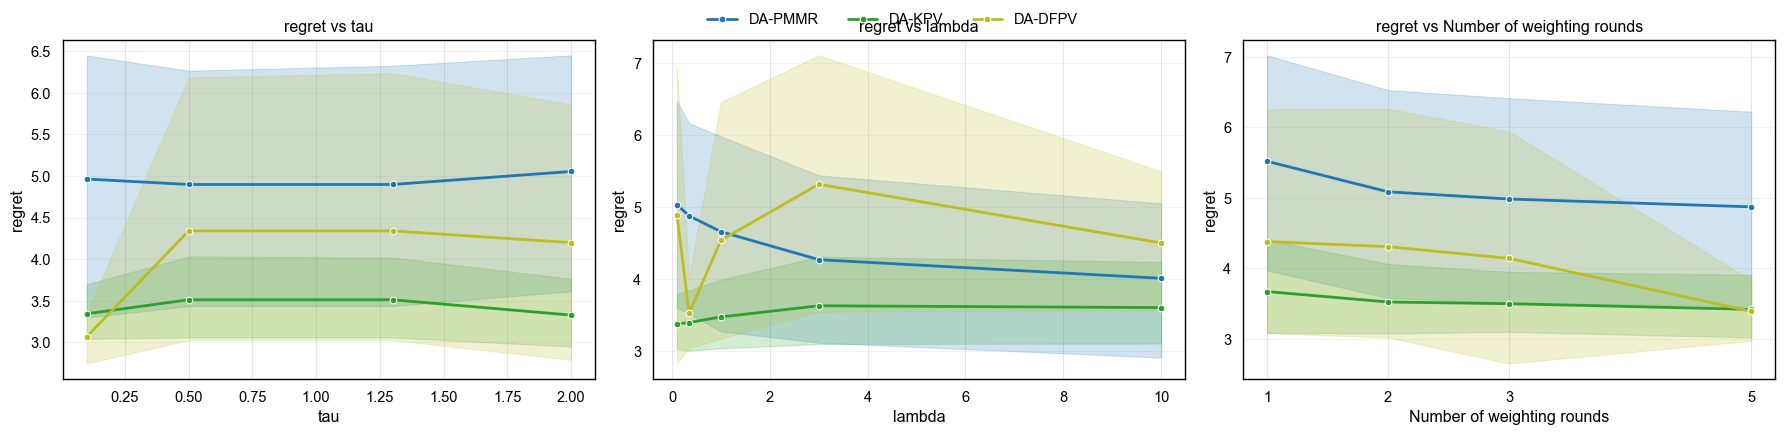

In [8]:
parameters_to_plot = [parameter for parameter in ["tau", "lam", "n_rounds"] if parameter in available_parameters]
if parameters_to_plot:
    fig, axes = plt.subplots(1, len(parameters_to_plot), figsize=(6.0 * len(parameters_to_plot), 4.4), squeeze=False)
    for ax, parameter in zip(axes.ravel(), parameters_to_plot):
        plot_ablation_metric_ci(
            metrics_df,
            metric=SELECTED_METRIC,
            split=DEFAULT_SPLIT,
            parameter=parameter,
            methods=METHODS_TO_PLOT,
            method_order=METHOD_ORDER,
            colors=METHOD_COLORS,
            labels=METHOD_LABELS,
            seeds=SEEDS_TO_ANALYZE,
            confidence=CONFIDENCE,
            n_boot=N_BOOT,
            ax=ax,
        )
    # Keep only one legend to avoid repeated entries.
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    for ax in axes.ravel():
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    if handles:
        mapped = [METHOD_LABELS.get(label, label) for label in labels]
        fig.legend(handles, mapped, loc="upper center", ncol=min(len(mapped), 4), frameon=False)
    fig.tight_layout()
    if SAVE_FIGURES:
        save_figure(fig, ANALYSIS_DIR / f"ablation_all_parameters_{SELECTED_METRIC}_{DEFAULT_SPLIT}.png")
        save_figure(fig, ANALYSIS_DIR / f"ablation_all_parameters_{SELECTED_METRIC}_{DEFAULT_SPLIT}.pdf")
    plt.show()

In [9]:
# Tables: mean and standard deviation (no CI) per ablation value and method
TABLE_PARAMETERS = ["tau", "lam", "n_rounds"]

table_base = metrics_df.copy()
if "split" in table_base.columns:
    table_base = table_base[table_base["split"].astype(str) == str(DEFAULT_SPLIT)].copy()
if METHODS_TO_PLOT is not None:
    table_base = table_base[table_base["method"].isin(METHODS_TO_PLOT)].copy()

table_base["metric_value"] = pd.to_numeric(table_base[SELECTED_METRIC], errors="coerce")
table_base = table_base.dropna(subset=["metric_value", "ablation_parameter", "ablation_value", "method"]).copy()

for parameter in TABLE_PARAMETERS:
    if parameter not in set(table_base["ablation_parameter"].astype(str)):
        print(f"Skipping table for {parameter}: not present in ablation table")
        continue

    param_df = table_base[table_base["ablation_parameter"].astype(str) == parameter].copy()
    if param_df.empty:
        print(f"Skipping table for {parameter}: no rows after filtering")
        continue

    summary_long = (
        param_df.groupby(["ablation_value", "method"], observed=True)["metric_value"]
        .agg(mean="mean", std="std")
        .reset_index()
    )

    method_order_for_table = [m for m in METHOD_ORDER if m in set(summary_long["method"].astype(str))]
    method_order_for_table += sorted(m for m in summary_long["method"].astype(str).unique() if m not in set(method_order_for_table))

    summary_long["method"] = pd.Categorical(summary_long["method"].astype(str), categories=method_order_for_table, ordered=True)
    summary_long = summary_long.sort_values(["ablation_value", "method"])

    summary_wide = summary_long.pivot(index="ablation_value", columns="method", values=["mean", "std"])
    summary_wide = summary_wide.sort_index(axis=0)
    summary_wide = summary_wide.reindex(columns=method_order_for_table, level=1)

    print(f"\n{parameter} - {SELECTED_METRIC} (mean/std over seeds)")
    display(summary_wide)



tau - regret (mean/std over seeds)


mean                                      std                           
method         Weighted PMMR Weighted KPV Weighted DFPV Weighted PMMR Weighted KPV Weighted DFPV
ablation_value                                                                                  
0.1                 4.964089     3.343446      3.067226      2.071041     0.468606      0.418634
0.5                 4.898293     3.512110      4.340265      1.986112     0.661261      2.297966
1.3                 4.898293     3.512110      4.340265      1.986112     0.661261      2.297966
2.0                 5.054550     3.327785      4.199134      1.934542     0.561484      2.169067


lam - regret (mean/std over seeds)


mean                                      std                           
method         Weighted PMMR Weighted KPV Weighted DFPV Weighted PMMR Weighted KPV Weighted DFPV
ablation_value                                                                                  
0.10                5.032239     3.372509      4.894238      1.931227     0.528645      2.771894
0.35                4.875833     3.392297      3.523162      1.887126     0.592921      0.674983
1.00                4.656128     3.469437      4.536453      1.874569     0.660729      2.276717
3.00                4.266892     3.625196      5.316748      1.622571     0.826525      2.508949
10.00               4.007298     3.599864      4.499097      1.553713     0.787940      1.297694


n_rounds - regret (mean/std over seeds)


mean                                      std                           
method         Weighted PMMR Weighted KPV Weighted DFPV Weighted PMMR Weighted KPV Weighted DFPV
ablation_value                                                                                  
1.0                 5.516320     3.668812      4.378175      2.070375     0.954499      2.292453
2.0                 5.082873     3.521210      4.305361      2.018241     0.679313      2.318424
3.0                 4.980787     3.496761      4.139413      1.992988     0.579451      2.256062
5.0                 4.870064     3.416501      3.388324      1.888552     0.614246      0.611895